## Dawn Andrei Pamesa
## TS31

## CART Decision Tree Regression: Boston Dataset

Dataset: Boston-1.csv (506 towns, 13 features, target = medv)

Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Objective of the Analysis

The goal is to predict medv, the median value of owner-occupied homes in $1000s, from the 13 other features of each town. The target is a number, so this is a regression problem and a CART regression tree is the model.

Load Data

In [2]:
df = pd.read_csv("Boston-1.csv", index_col=0)
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [3]:
print("Shape :", df.shape)

Shape : (506, 14)


In [4]:
print("Missing values :", df.isnull().sum().sum())
print("Duplicate rows :", df.duplicated().sum())

Missing values : 0
Duplicate rows : 0


In [5]:
df.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


Balanced or Imbalanced Data

The target is a number, so there are no classes to count. Balance is checked by looking at how medv is spread, and by grouping it into low, mid and high price groups.

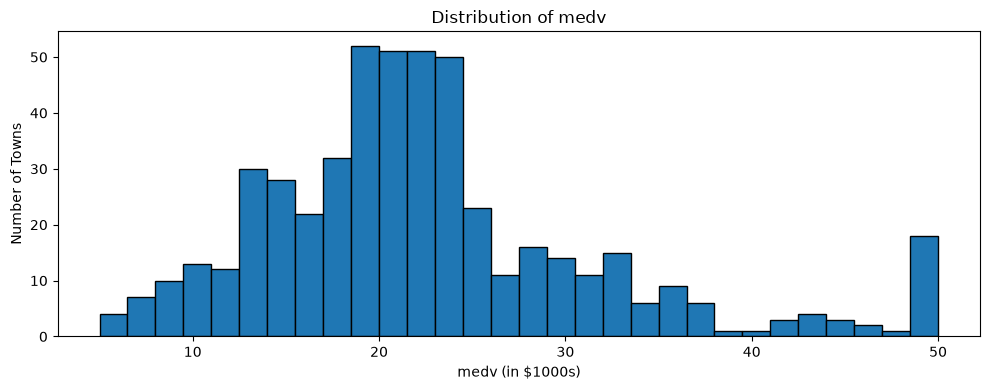

In [6]:
plt.figure(figsize=(10, 4))
plt.hist(df['medv'], bins=30, edgecolor='black')
plt.title("Distribution of medv")
plt.xlabel("medv (in $1000s)")
plt.ylabel("Number of Towns")
plt.tight_layout()
plt.show()

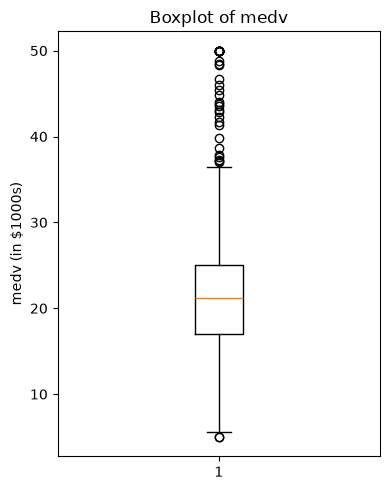

In [7]:
plt.figure(figsize=(4, 5))
plt.boxplot(df['medv'])
plt.title("Boxplot of medv")
plt.ylabel("medv (in $1000s)")
plt.tight_layout()
plt.show()

In [8]:
print("Skewness :", round(df['medv'].skew(), 2))
print("Towns capped at 50 :", (df['medv'] == 50).sum())

Skewness : 1.11
Towns capped at 50 : 16


In [9]:
price_group = pd.cut(df['medv'], bins=[0, 20, 30, 50], labels=["Low (up to 20)", "Mid (over 20 to 30)", "High (over 30)"])
price_group.value_counts()

medv
Low (up to 20)         215
Mid (over 20 to 30)    207
High (over 30)          84
Name: count, dtype: int64

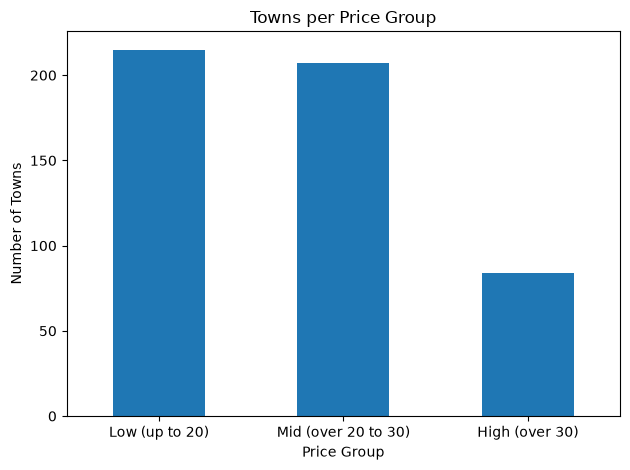

In [10]:
price_group.value_counts().plot(kind='bar')
plt.title("Towns per Price Group")
plt.xlabel("Price Group")
plt.ylabel("Number of Towns")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

medv is right-skewed (skewness 1.11), with a long tail of expensive towns and 16 towns piled up at the cap of 50. By price group, the low group (215 towns) and the mid group (207 towns) are about the same size, but the high group has only 84 towns, around 17% of the data. So the data is moderately imbalanced toward cheaper towns, and the tree has fewer examples to learn from for the expensive ones. No resampling is needed for a regression tree, but it is something to watch in the errors.

Features and Target

In [11]:
X = df.drop('medv', axis='columns')

In [12]:
y = df['medv']

Train and Test Split

The test set is set aside first so that feature importance and tuning only use the training data.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
print("Train shape :", X_train.shape)
print("Test shape  :", X_test.shape)

Train shape : (404, 13)
Test shape  : (102, 13)


Feature Importance

In [15]:
tree_all = DecisionTreeRegressor(random_state=42)
tree_all.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [16]:
importance = pd.DataFrame({"Feature": X_train.columns, "Importance": tree_all.feature_importances_})
importance = importance.sort_values("Importance", ascending=False)
importance

,Feature,Importance
5,rm,6.057924e-01
12,lstat,2.130401e-01
7,dis,6.460377e-02
0,crim,5.147472e-02
6,age,1.380815e-02
9,tax,1.278916e-02
11,black,1.148568e-02
10,ptratio,1.110779e-02
4,nox,6.320598e-03
2,indus,6.046697e-03


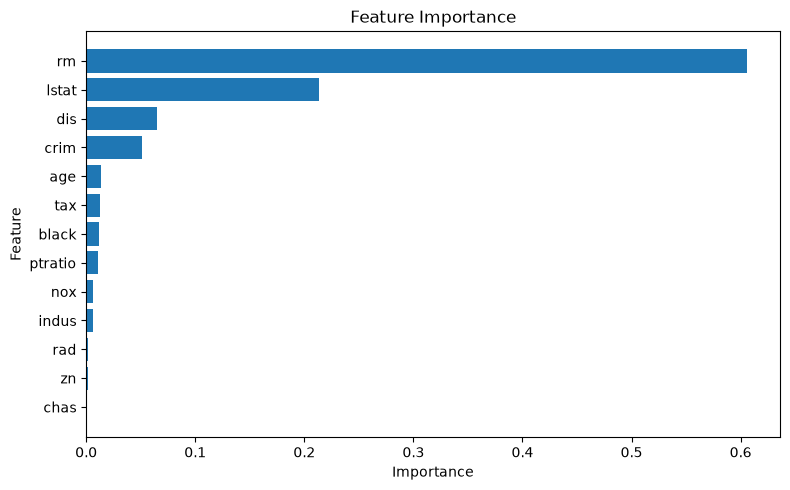

In [17]:
plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Feature Selection

In [18]:
# A cut-off of 0.05 keeps the features that carry most of the importance.
selected = importance[importance["Importance"] >= 0.05]["Feature"].tolist()
print("Selected features :", selected)
print("Importance kept   :", round(importance[importance["Importance"] >= 0.05]["Importance"].sum(), 3))

Selected features : ['rm', 'lstat', 'dis', 'crim']
Importance kept   : 0.935


In [19]:
X_train_sel = X_train[selected]
X_test_sel = X_test[selected]

rm (0.606) and lstat (0.213) carry about 82% of the importance on their own. dis (0.065) and crim (0.051) come next, and the other nine features are each 0.014 or less, with chas close to 0. The four selected features keep 93.5% of the total importance, so the other nine are dropped.

K-Fold Cross-Validation

Besides the hold-out test set, the training data is split with 5-fold cross-validation, which is used to tune the model and to check it.

In [20]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

Tune the CART Regression Model

In [21]:
param_grid = {"criterion": ["squared_error", "absolute_error"],
              "max_depth": [3, 4, 5, 6, 8],
              "min_samples_split": [2, 10, 20],
              "min_samples_leaf": [1, 5, 10]}

In [22]:
grid = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=kf, scoring="r2")
grid.fit(X_train_sel, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'absolute_error'], 'max_depth': [3, 4, ...], 'min_samples_leaf': [1, 5, ...], 'min_samples_split': [2, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchang

In [23]:
print("Best parameters :", grid.best_params_)
print("Best CV R2      :", round(grid.best_score_, 3))

Best parameters : {'criterion': 'absolute_error', 'max_depth': 6, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV R2      : 0.744


In [24]:
cart = grid.best_estimator_

In [25]:
cv_scores = cross_val_score(cart, X_train_sel, y_train, cv=kf, scoring="r2")
print("R2 per fold :", cv_scores.round(3))
print("Mean R2     :", round(cv_scores.mean(), 3))
print("Std R2      :", round(cv_scores.std(), 3))

R2 per fold : [0.656 0.882 0.661 0.773 0.749]
Mean R2     : 0.744
Std R2      : 0.083


Evaluation Metrics

In [26]:
y_train_pred = cart.predict(X_train_sel)
y_test_pred = cart.predict(X_test_sel)

In [27]:
print("Train R2   :", round(r2_score(y_train, y_train_pred), 3))
print("Train MAE  :", round(mean_absolute_error(y_train, y_train_pred), 3))
print("Train MSE  :", round(mean_squared_error(y_train, y_train_pred), 3))
print("Train RMSE :", round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 3))

Train R2   : 0.806
Train MAE  : 2.326
Train MSE  : 16.88
Train RMSE : 4.109


In [28]:
print("Test R2    :", round(r2_score(y_test, y_test_pred), 3))
print("Test MAE   :", round(mean_absolute_error(y_test, y_test_pred), 3))
print("Test MSE   :", round(mean_squared_error(y_test, y_test_pred), 3))
print("Test RMSE  :", round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 3))

Test R2    : 0.751
Test MAE   : 2.719
Test MSE   : 18.262
Test RMSE  : 4.273


Generalized, Overfit or Underfit

In [29]:
plain_tree = DecisionTreeRegressor(random_state=42)
plain_tree.fit(X_train_sel, y_train)
print("Unpruned tree depth    :", plain_tree.get_depth())
print("Unpruned tree train R2 :", round(plain_tree.score(X_train_sel, y_train), 3))
print("Unpruned tree test R2  :", round(plain_tree.score(X_test_sel, y_test), 3))
plain_cv = cross_val_score(plain_tree, X_train_sel, y_train, cv=kf, scoring="r2")
print("Unpruned tree CV R2    :", round(plain_cv.mean(), 3))

Unpruned tree depth    : 19
Unpruned tree train R2 : 1.0
Unpruned tree test R2  : 0.796
Unpruned tree CV R2    : 0.601


In [30]:
print("Tuned tree train R2 :", round(cart.score(X_train_sel, y_train), 3))
print("Tuned tree CV R2    :", round(cv_scores.mean(), 3))
print("Tuned tree test R2  :", round(cart.score(X_test_sel, y_test), 3))
print("Train - test gap    :", round(cart.score(X_train_sel, y_train) - cart.score(X_test_sel, y_test), 3))

Tuned tree train R2 : 0.806
Tuned tree CV R2    : 0.744
Tuned tree test R2  : 0.751
Train - test gap    : 0.055


The unpruned tree grew to depth 19 and scored a train R2 of 1.0, which means it memorized the training data. Its CV R2 is only about 0.60, so it overfits. Its test R2 of 0.796 looks higher than the tuned tree's, but that is a single split of only 102 towns, while the cross-validation scores cover every training town. The tuned tree has a train R2 of 0.806, a CV R2 of 0.744 and a test R2 of 0.751. The gap between train and test is only 0.055 and the CV and test scores agree, so the tuned model generalized. It is not underfit either, since it explains about 75% of the variation in medv on data it has not seen.

Improve the Model

In [31]:
param_grid2 = {"criterion": [grid.best_params_["criterion"]],
               "max_depth": [4, 5, 6, 7],
               "min_samples_split": [2, 10],
               "min_samples_leaf": [3, 5, 8, 10, 12],
               "ccp_alpha": [0, 0.01, 0.05, 0.1, 0.2]}

In [32]:
grid2 = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid2, cv=kf, scoring="r2")
grid2.fit(X_train_sel, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': [0, 0.01, ...], 'criterion': ['absolute_error'], 'max_depth': [4, 5, ...], 'min_samples_leaf': [3, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support 

In [33]:
print("Best parameters :", grid2.best_params_)
print("Best CV R2      :", round(grid2.best_score_, 3))

Best parameters : {'ccp_alpha': 0, 'criterion': 'absolute_error', 'max_depth': 6, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV R2      : 0.744


In [34]:
cart2 = grid2.best_estimator_

In [35]:
print("First model  CV R2 :", round(grid.best_score_, 3), "| train R2 :", round(cart.score(X_train_sel, y_train), 3), "| test R2 :", round(cart.score(X_test_sel, y_test), 3))
print("Second model CV R2 :", round(grid2.best_score_, 3), "| train R2 :", round(cart2.score(X_train_sel, y_train), 3), "| test R2 :", round(cart2.score(X_test_sel, y_test), 3))

First model  CV R2 : 0.744 | train R2 : 0.806 | test R2 : 0.751
Second model CV R2 : 0.744 | train R2 : 0.806 | test R2 : 0.751


The model already generalizes, so a second, finer grid was tried with ccp_alpha pruning added. It picked the same settings as the first model (ccp_alpha = 0), so the scores did not change. The first model is kept as the final model.

Final Model Metrics

In [36]:
final = cart
y_test_pred = final.predict(X_test_sel)

In [37]:
print("Test R2   :", round(r2_score(y_test, y_test_pred), 3))
print("Test MAE  :", round(mean_absolute_error(y_test, y_test_pred), 3))
print("Test MSE  :", round(mean_squared_error(y_test, y_test_pred), 3))
print("Test RMSE :", round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 3))

Test R2   : 0.751
Test MAE  : 2.719
Test MSE  : 18.262
Test RMSE : 4.273


Decision Tree Visualization

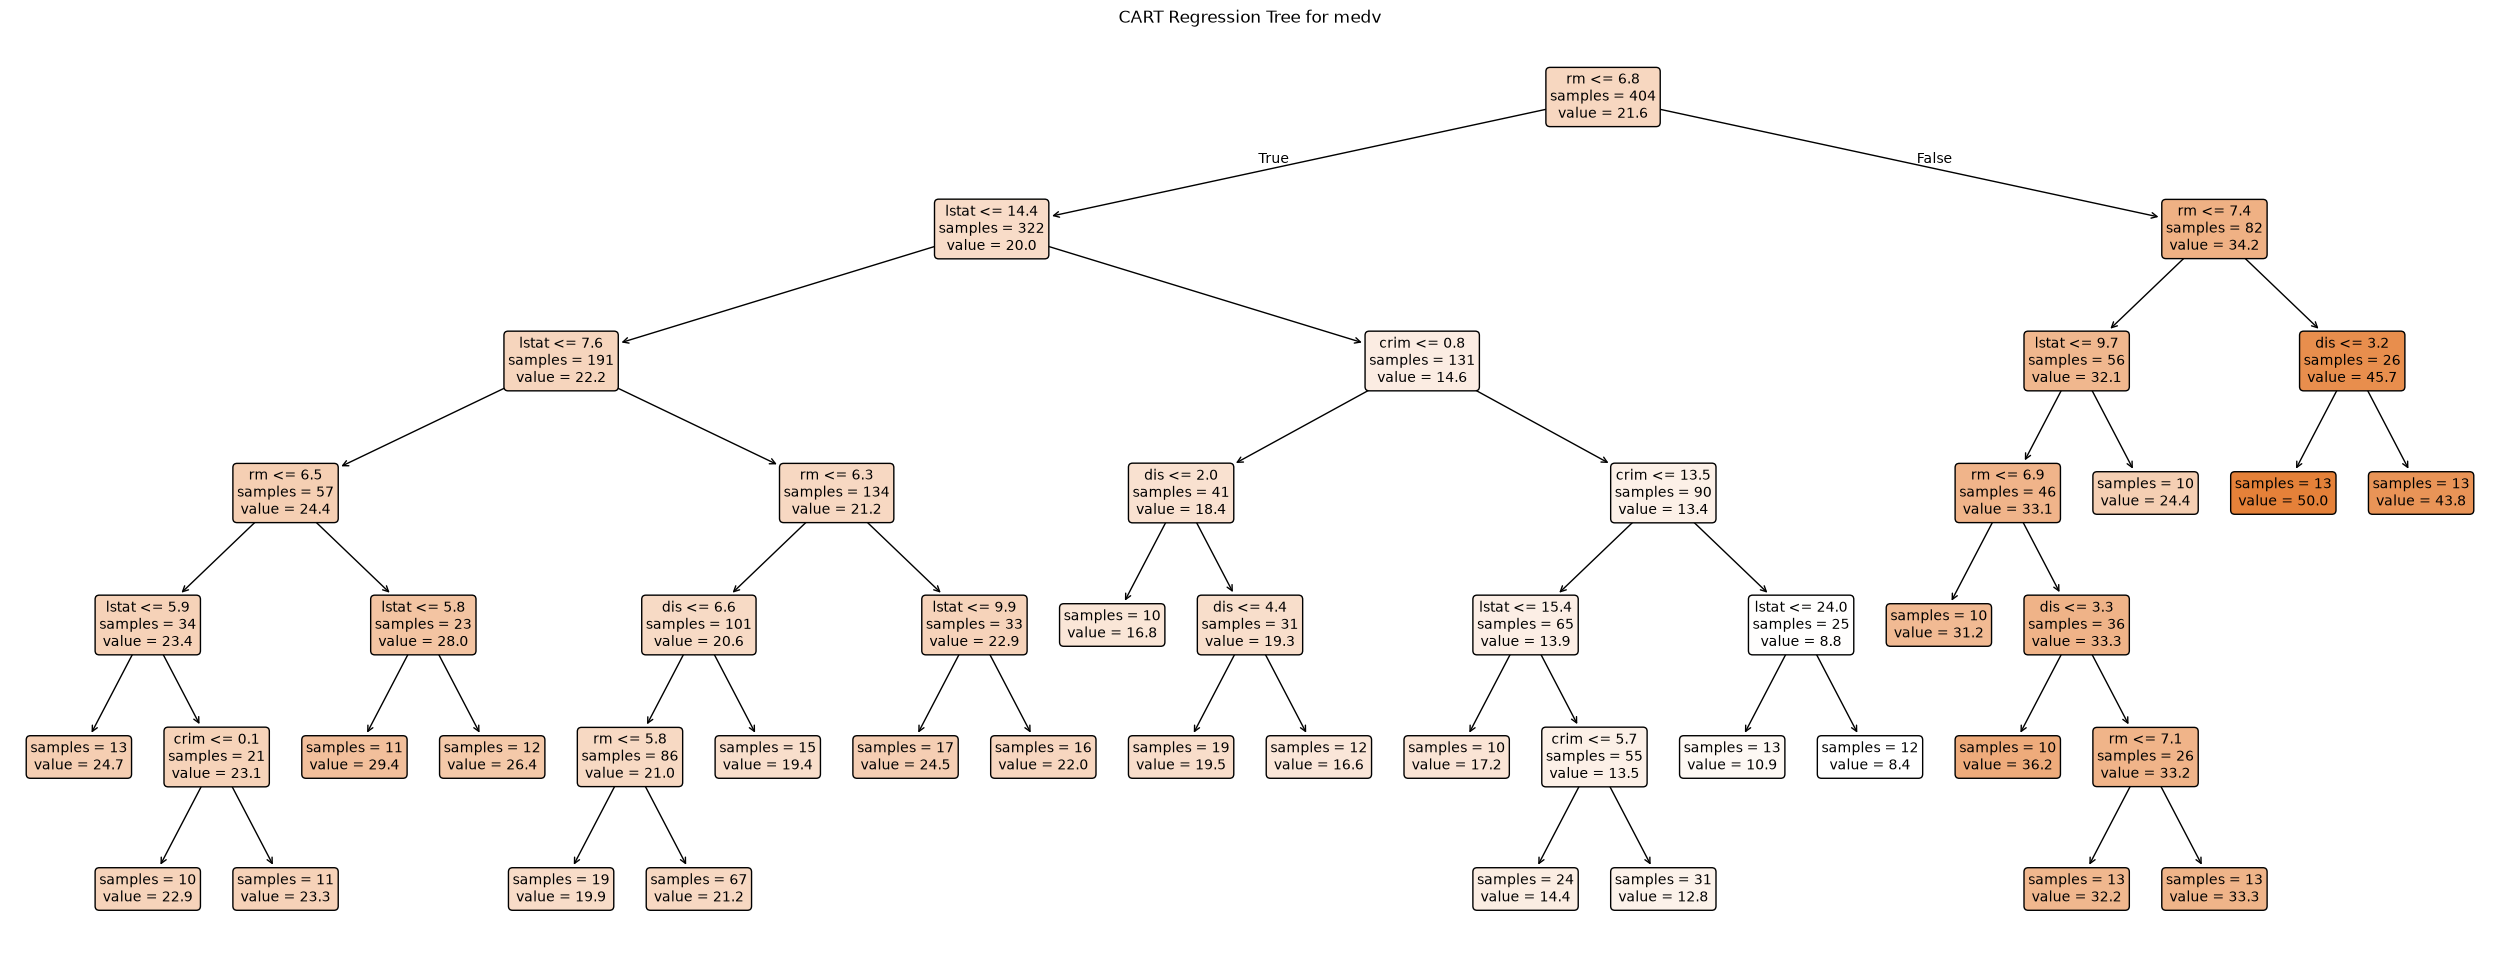

In [38]:
plt.figure(figsize=(32, 12))
plot_tree(final, feature_names=selected, filled=True, rounded=True, impurity=False, precision=1, fontsize=10)
plt.title("CART Regression Tree for medv")
plt.show()

Test with New Data

In [39]:
new_towns = pd.DataFrame({"rm": [7.2, 6.0, 5.0],
                          "lstat": [4.0, 12.0, 25.0],
                          "dis": [5.0, 3.5, 2.0],
                          "crim": [0.05, 0.5, 8.0]})
new_towns

,rm,lstat,dis,crim
0,7.2,4.0,5.0,0.05
1,6.0,12.0,3.5,0.50
2,5.0,25.0,2.0,8.00


In [40]:
new_towns["Predicted medv"] = final.predict(new_towns[selected])
new_towns

,rm,lstat,dis,crim,Predicted medv
0,7.2,4.0,5.0,0.05,33.3
1,6.0,12.0,3.5,0.50,21.2
2,5.0,25.0,2.0,8.00,12.8


The three new towns are made up. The first has large homes (7.2 rooms), a low share of lower-status residents and low crime, and the model predicts about 33.3 ($33,300). The second is an average town and is predicted at about 21.2. The third has small homes (5 rooms), a high share of lower-status residents and higher crime, and is predicted at about 12.8.

Findings and Insights

The target medv is spread unevenly: it is right-skewed, 16 towns are capped at 50, and only about 17% of the towns are in the high price group. Feature importance showed that rm and lstat do most of the work, so the tree was built on just rm, lstat, dis and crim. The best CART regression tree has a depth of 6, uses absolute_error, and needs at least 10 towns in each leaf. With 5-fold cross-validation it scored a mean R2 of 0.744, and on the test set it scored an R2 of 0.751, an MAE of 2.719 and an RMSE of 4.273. In plain terms, its predictions are off by about $2,700 on average. The fold scores ranged from 0.656 to 0.882, so the result depends on which towns land in the training folds, and a single tree is not very stable. Pruning the tree with hyperparameters mattered: the unpruned tree had a CV R2 of only about 0.60. The new-town predictions follow the same pattern: more rooms and a lower share of lower-status residents mean a higher home value.